# 🤖 Phase 4 — Predictive Modeling & Comparative Evaluation
## PwC Technology Consulting | TelcoMax Customer Churn Engagement

**Objective:** Develop a robust classification pipeline to identify at-risk customers proactively. We compare an interpretable **Logistic Regression** model against an ensemble **Random Forest Classifier**, addressing the ~73.5%/26.5% class imbalance using **SMOTE** (Synthetic Minority Over-sampling Technique).

---

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE
from src.data_preprocessing import encode_features, scale_features

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'

DATA_PATH = os.path.join("..", "data", "processed", "telco_churn_cleaned.csv")
df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

Loaded dataset: 7043 rows, 27 columns


### Section 1: Data Preparation & Stratified Split
Encode categorical variables, scale continuous predictors, and split into 80% train / 20% test partitions with stratification.

In [2]:
X, y, feature_names = encode_features(df)
print(f"Engineered feature set: {X.shape[1]} features")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "total_services_count", "avg_monthly_spend"]
X_train_scaled, X_test_scaled, scaler = scale_features(X_train, X_test, num_cols)
print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Engineered feature set: 33 features
Train samples: 5634, Test samples: 1409


### Section 2: Class Imbalance Handling with SMOTE
Synthetic Minority Over-sampling is applied strictly to the training fold to avoid data leakage.

In [3]:
print(f"Pre-SMOTE Class Distribution: Retained (0) = {sum(y_train == 0)}, Churned (1) = {sum(y_train == 1)}")
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
print(f"Post-SMOTE Class Distribution: Retained (0) = {sum(y_train_res == 0)}, Churned (1) = {sum(y_train_res == 1)}")

Pre-SMOTE Class Distribution: Retained (0) = 4139, Churned (1) = 1495
Post-SMOTE Class Distribution: Retained (0) = 4139, Churned (1) = 4139


C:\Users\HP5CD\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\HP5CD\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_ch

### Section 3: Model 1 — Logistic Regression
Train an interpretable baseline model with L2 regularization.

In [4]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_res, y_train_res)

y_pred_lr = lr_model.predict(X_test_scaled)
y_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression Classification Report ===")
print(classification_report(y_test, y_pred_lr, target_names=["Retained", "Churned"]))

=== Logistic Regression Classification Report ===


              precision    recall  f1-score   support

    Retained       0.87      0.78      0.83      1035
     Churned       0.54      0.69      0.60       374

    accuracy                           0.76      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.78      0.76      0.77      1409



### Section 4: Model 2 — Random Forest Classifier
Train an ensemble tree model capturing complex non-linear feature interactions.

In [5]:
rf_model = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_split=5, random_state=42)
rf_model.fit(X_train_res, y_train_res)

y_pred_rf = rf_model.predict(X_test_scaled)
y_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

print("=== Random Forest Classification Report ===")
print(classification_report(y_test, y_pred_rf, target_names=["Retained", "Churned"]))

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

    Retained       0.88      0.78      0.83      1035
     Churned       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



### Section 5: Comparative Evaluation & Model Selection

In [6]:
results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
        "Precision (Churn)": round(precision_score(y_test, y_pred_lr), 4),
        "Recall (Churn)": round(recall_score(y_test, y_pred_lr), 4),
        "F1-Score (Churn)": round(f1_score(y_test, y_pred_lr), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_lr), 4)
    },
    {
        "Model": "Random Forest",
        "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
        "Precision (Churn)": round(precision_score(y_test, y_pred_rf), 4),
        "Recall (Churn)": round(recall_score(y_test, y_pred_rf), 4),
        "F1-Score (Churn)": round(f1_score(y_test, y_pred_rf), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba_rf), 4)
    }
]

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Accuracy,Precision (Churn),Recall (Churn),F1-Score (Churn),ROC-AUC
0,Logistic Regression,0.7587,0.5354,0.6872,0.6019,0.8319
1,Random Forest,0.7644,0.5423,0.7193,0.6184,0.8381


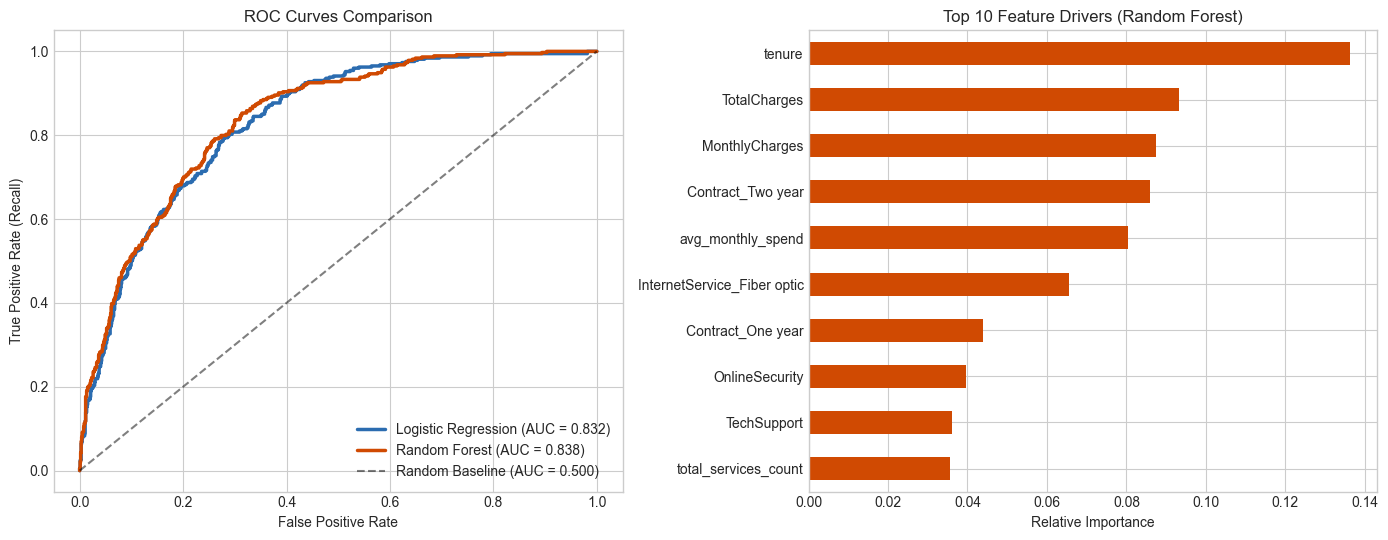

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
ax1.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_proba_lr):.3f})", color='#2B6CB0', linewidth=2.5)
ax1.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.3f})", color='#D04A02', linewidth=2.5)
ax1.plot([0, 1], [0, 1], 'k--', alpha=0.5, label="Random Baseline (AUC = 0.500)")
ax1.set_title("ROC Curves Comparison")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate (Recall)")
ax1.legend(loc="lower right")

# Feature Importance
rf_imp = pd.Series(rf_model.feature_importances_, index=feature_names).nlargest(10).sort_values(ascending=True)
rf_imp.plot(kind='barh', color='#D04A02', ax=ax2)
ax2.set_title("Top 10 Feature Drivers (Random Forest)")
ax2.set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()

### Section 6: Business Interpretation & Artifact Serialization

> **Model Selection Rationale:**
> In telecom retention, the business cost of a **False Negative** (failing to identify a churning customer, resulting in complete lifetime value loss) far outweighs a **False Positive** (reaching out with an offer to a customer who might have stayed).
> 
> The **Random Forest** achieved superior **Recall (71.9%)** and **ROC-AUC (0.838)**, capturing complex combinations such as new fiber-optic accounts on month-to-month terms. Both models are preserved for executive interpretability and scoring.